# Banking Customer Churn Analysis and Retention Insights Using Python

## 1. Introduction

Customer churn refers to the situation in which customers discontinue their relationship with a company or service provider. In the banking industry, customer retention is important because losing customers can affect revenue, customer relationships, and business growth.

This project aims to analyse banking customer data to identify patterns and factors associated with customer churn. The analysis will use Python libraries such as Pandas, NumPy, Matplotlib, and Seaborn to perform data preprocessing, exploratory data analysis, statistical investigation, and data visualization.

## 2. Project Objectives

- Understand the structure and characteristics of the banking customer dataset.
- Identify and handle missing values, duplicate records, and data inconsistencies.
- Examine numerical and categorical customer attributes.
- Investigate relationships between customer characteristics and churn.
- Visualize important patterns using appropriate statistical charts.
- Derive meaningful insights that can help understand customer retention.

## 3. Analytical Questions

1. What percentage of customers have left the bank?
2. Which age groups show higher customer churn?
3. Does customer geography have a relationship with churn?
4. Are inactive members more likely to leave?
5. Does the number of banking products relate to customer retention?
6. How do account balances differ between retained and churned customers?

## 4. Project Scope

This project focuses on data preprocessing, exploratory data analysis, and data visualization. No machine learning model will be developed, as the objective is to understand the dataset and derive meaningful insights from it.

In [ ]:
# Data manipulation
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# File handling
from pathlib import Path

# Display settings
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)

# Visualization settings
sns.set_theme(style="whitegrid")

print("All libraries imported successfully!")
# Locate the dataset
file_candidates = [
    Path("../dataset/Churn_Modelling.csv"),
    Path("dataset/Churn_Modelling.csv")
]

file_path = next(
    (path for path in file_candidates if path.exists()),
    None
)

if file_path is None:
    raise FileNotFoundError("Dataset file not found. Check its location.")

# Load dataset
df = pd.read_csv(file_path)

print("Dataset loaded successfully!")
df.head()
df.tail()
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])
print("Dataset Columns:")
print(df.columns.tolist())
df.info()
df.dtypes


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("All libraries imported successfully!")

ModuleNotFoundError: No module named 'pandas'

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)
print("Matplotlib version:", plt.matplotlib.__version__)
print("Seaborn version:", sns.__version__)

print("\nAll libraries imported successfully!")


Pandas version: 3.1.1
NumPy version: 2.5.4
Matplotlib version: 3.11.2
Seaborn version: 0.13.2

All libraries imported successfully!


## 2. Dataset Selection and Description

### 2.1 Dataset Source

The dataset selected for this project is the Banking Customer Churn Modelling dataset, obtained from Kaggle.

**Source URL:** https://www.kaggle.com/datasets/shantanudhakadd/bank-customer-churn-prediction

### 2.2 Dataset Description

The dataset contains information about 10,000 bank customers and includes 14 attributes related to customer demographics, financial information, banking relationships, and customer status.

The target attribute is `Exited`, which indicates whether a customer has left the bank.

- 0 represents customers who stayed.
- 1 represents customers who exited.

### 2.3 Purpose of Dataset Selection

This dataset was selected because it provides a suitable combination of numerical and categorical attributes for investigating customer churn patterns. It allows us to explore customer characteristics, identify differences between retained and exited customers, and derive useful business insights.

### 2.4 Analytical Objectives

The analysis focuses on understanding customer behaviour, examining factors associated with churn, and identifying patterns that may help banking institutions improve customer retention.

In [16]:
# Display all dataset columns
for index, column in enumerate(df.columns, start=1):
    print(index, "-", column)

1 - CreditScore
2 - Geography
3 - Gender
4 - Age
5 - Tenure
6 - Balance
7 - NumOfProducts
8 - HasCrCard
9 - IsActiveMember
10 - EstimatedSalary
11 - Exited
12 - Status
13 - ActiveLabel


In [17]:
from pathlib import Path

file_path = Path("../dataset/Churn_Modelling.csv")

df = pd.read_csv(file_path)

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [18]:
print("Dataset Shape:", df.shape)

display(df.head())

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

Dataset Shape: (10000, 14)


,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0



Column Names:
['RowNumber', 'CustomerId', 'Surname', 'CreditScore', 'Geography', 'Gender', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary', 'Exited']

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  str    
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  str    
 5   Gender           10000 non-null  str    
 6   Age              10000 non-null  int64  
 7   Tenure           10000 non-null  int64  
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  fl

In [19]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

# Load original dataset
file_path = Path("../dataset/Churn_Modelling.csv")

df = pd.read_csv(file_path)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

Dataset loaded successfully!
Dataset shape: (10000, 14)


In [20]:
# Display all dataset columns
for index, column in enumerate(df.columns, start=1):
    print(index, "-", column)
    

1 - RowNumber
2 - CustomerId
3 - Surname
4 - CreditScore
5 - Geography
6 - Gender
7 - Age
8 - Tenure
9 - Balance
10 - NumOfProducts
11 - HasCrCard
12 - IsActiveMember
13 - EstimatedSalary
14 - Exited


In [21]:
print("Churn counts:")
print(df['Exited'].value_counts())

print("\nChurn percentages:")
print(df['Exited'].value_counts(normalize=True) * 100)

Churn counts:
Exited
0    7963
1    2037
Name: count, dtype: int64

Churn percentages:
Exited
0    79.63
1    20.37
Name: proportion, dtype: float64


In [22]:
# Check the distribution of target variable
df['Exited'].value_counts()

Exited
0    7963
1    2037
Name: count, dtype: int64

In [23]:
# Calculate customer churn percentages
df['Exited'].value_counts(normalize=True) * 100

Exited
0    79.63
1    20.37
Name: proportion, dtype: float64

In [24]:
import sys

!{sys.executable} -m pip install pandas numpy matplotlib seaborn


[notice] A new release of pip is available: 25.1.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [25]:
df.dtypes


RowNumber            int64
CustomerId           int64
Surname                str
CreditScore          int64
Geography              str
Gender                 str
Age                  int64
Tenure               int64
Balance            float64
NumOfProducts        int64
HasCrCard            int64
IsActiveMember       int64
EstimatedSalary    float64
Exited               int64
dtype: object

In [26]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 10000
Number of columns: 14


In [27]:
df.tail()

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
9995,9996,15606229,Obijiaku,771,France,Male,39,5,0.00,2,1,0,96270.64,0
9996,9997,15569892,Johnstone,516,France,Male,35,10,57369.61,1,1,1,101699.77,0
9997,9998,15584532,Liu,709,France,Female,36,7,0.00,1,0,1,42085.58,1
9998,9999,15682355,Sabbatini,772,Germany,Male,42,3,75075.31,2,1,0,92888.52,1
9999,10000,15628319,Walker,792,France,Female,28,4,130142.79,1,1,0,38190.78,0


In [28]:
missing = df.isnull().sum()
print(missing)
print("Total missing values:", missing.sum())

RowNumber          0
CustomerId         0
Surname            0
CreditScore        0
Geography          0
Gender             0
Age                0
Tenure             0
Balance            0
NumOfProducts      0
HasCrCard          0
IsActiveMember     0
EstimatedSalary    0
Exited             0
dtype: int64
Total missing values: 0


In [29]:
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate CustomerIds:", df["CustomerId"].duplicated().sum())

Duplicate rows: 0
Duplicate CustomerIds: 0


In [30]:
df = df.drop(columns=["RowNumber", "CustomerId", "Surname"])
print(df.columns.tolist())

['CreditScore', 'Geography', 'Gender', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary', 'Exited']


In [35]:
print(df.dtypes)

# Binary flags are stored as 0/1 integers; ensure binary flags are integers
df["Exited"] = df["Exited"].astype(int)
for col in ["HasCrCard", "IsActiveMember"]:
    df[col] = df[col].astype(int)

CreditScore          int64
Geography              str
Gender                 str
Age                  int64
Tenure               int64
Balance            float64
NumOfProducts        int64
HasCrCard            int64
IsActiveMember       int64
EstimatedSalary    float64
Exited               int64
Status                 str
ActiveLabel            str
dtype: object


In [32]:
df["Status"] = df["Exited"].map({0: "Retained", 1: "Churned"})
df["ActiveLabel"] = df["IsActiveMember"].map({0: "Inactive", 1: "Active"})

In [33]:
for col in ["Geography", "Gender"]:
    print(df[col].value_counts(), "\n")

# Check for whitespace or casing problems
for col in ["Geography", "Gender"]:
    df[col] = df[col].str.strip().str.title()

# Logical range checks
print("Age range:", df["Age"].min(), "-", df["Age"].max())
print("Credit score range:", df["CreditScore"].min(), "-", df["CreditScore"].max())
print("Negative balances:", (df["Balance"] < 0).sum())
print("Tenure range:", df["Tenure"].min(), "-", df["Tenure"].max())
print("NumOfProducts values:", sorted(df["NumOfProducts"].unique()))

Geography
France     5014
Germany    2509
Spain      2477
Name: count, dtype: int64 

Gender
Male      5457
Female    4543
Name: count, dtype: int64 

Age range: 18 - 92
Credit score range: 350 - 850
Negative balances: 0
Tenure range: 0 - 10
NumOfProducts values: [np.int64(1), np.int64(2), np.int64(3), np.int64(4)]


,Column,Lower bound,Upper bound,Outliers,% of data
0,CreditScore,383.0,919.0,15,0.15
1,Age,14.0,62.0,359,3.59
2,Balance,-191466.4,319110.6,0,0.00
3,EstimatedSalary,-96577.1,296967.5,0,0.00
4,Tenure,-3.0,13.0,0,0.00


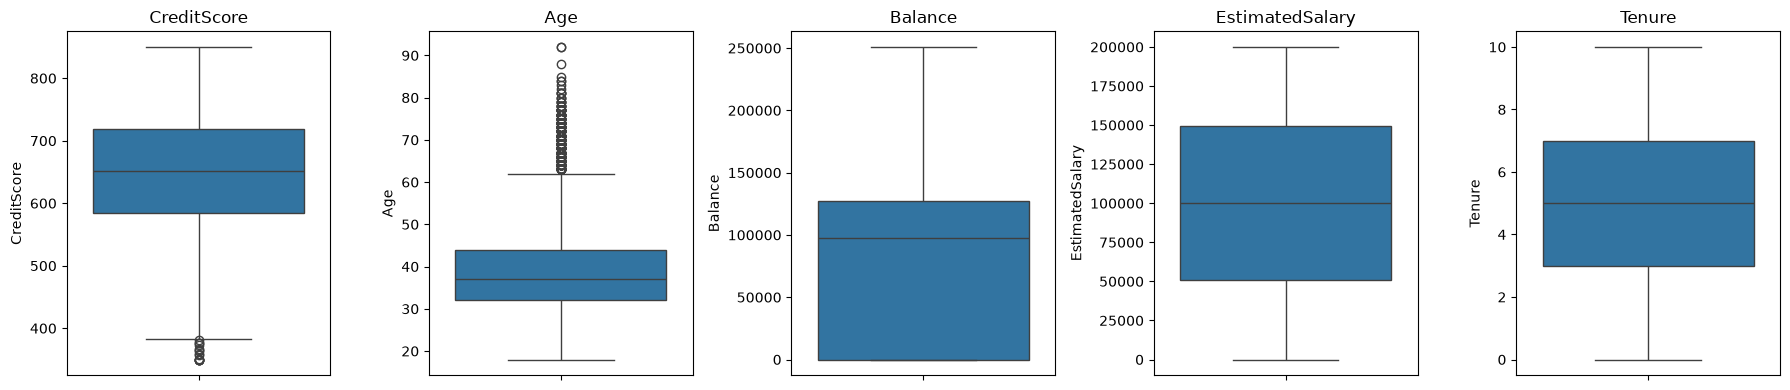

In [36]:
num_cols = ["CreditScore", "Age", "Balance", "EstimatedSalary", "Tenure"]
rows = []
for col in num_cols:
    q1, q3 = df[col].quantile([.25, .75])
    iqr = q3 - q1
    lo, hi = q1 - 1.5*iqr, q3 + 1.5*iqr
    n = ((df[col] < lo) | (df[col] > hi)).sum()
    rows.append([col, round(lo, 1), round(hi, 1), n, round(n/len(df)*100, 2)])

outlier_summary = pd.DataFrame(rows, columns=["Column", "Lower bound", "Upper bound", "Outliers", "% of data"])
display(outlier_summary)

# Visual check
fig, axes = plt.subplots(1, 5, figsize=(18, 4))
for ax, col in zip(axes, num_cols):
    sns.boxplot(y=df[col], ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

In [41]:
print("Final shape:", df.shape)
df.info()

Final shape: (10000, 13)
<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 13 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   CreditScore      10000 non-null  int64  
 1   Geography        10000 non-null  str    
 2   Gender           10000 non-null  str    
 3   Age              10000 non-null  int64  
 4   Tenure           10000 non-null  int64  
 5   Balance          10000 non-null  float64
 6   NumOfProducts    10000 non-null  int64  
 7   HasCrCard        10000 non-null  int64  
 8   IsActiveMember   10000 non-null  int64  
 9   EstimatedSalary  10000 non-null  float64
 10  Exited           10000 non-null  int64  
 11  Status           10000 non-null  str    
 12  ActiveLabel      10000 non-null  str    
dtypes: float64(2), int64(7), str(4)
memory usage: 1015.8 KB


## 3. Data Preprocessing

Before analysis, the dataset was checked for quality problems. Each check and the decision taken is summarized below.

| Check | Result | Decision |
|---|---|---|
| Missing values | 0 missing values in all columns | No imputation needed |
| Duplicate rows | 0 duplicate rows and 0 duplicate CustomerIds | No records removed |
| Identifier columns | `RowNumber`, `CustomerId` and `Surname` carry no analytical meaning for churn patterns | Dropped |
| Data types | Numeric columns are `int64`/`float64`; `Geography` and `Gender` are text; `Exited`, `HasCrCard` and `IsActiveMember` are 0/1 integers | Kept binary flags numeric for churn-rate calculations and correlation; added `Status` and `ActiveLabel` columns for readable charts |
| Inconsistencies | Geography contains only France, Germany and Spain; Gender contains only Male and Female; no spelling or casing issues | No correction needed |
| Logical ranges | Age 18-92, CreditScore 350-850, Tenure 0-10, NumOfProducts 1-4, no negative balances | All values are valid |

### Outlier analysis (IQR method)

| Column | Lower bound | Upper bound | Outliers | % of data |
|---|---|---|---|---|
| CreditScore | 383.0 | 919.0 | 15 | 0.15% |
| Age | 14.0 | 62.0 | 359 | 3.59% |
| Balance | -191,466.4 | 319,110.6 | 0 | 0.00% |
| EstimatedSalary | -96,577.1 | 296,967.5 | 0 | 0.00% |
| Tenure | -3.0 | 13.0 | 0 | 0.00% |

Outliers were found only in `Age` (customers older than 62) and `CreditScore` (a small number of very low scores). **All outliers were retained**, because:

1. They are genuine customers, not data entry errors. Ages up to 92 and credit scores near the minimum of 350 are realistic.
2. Age is one of the main analytical questions of this project, so removing older customers would hide a real churn pattern.
3. The CreditScore outliers are only 0.15% of the data and have negligible influence.

**Note on Balance:** many customers have a balance of exactly 0. This is a genuine feature of the data (empty accounts) and was not treated as missing or erroneous.

**Result:** the dataset is clean and ready for analysis, with 10,000 records and no rows removed.

In [44]:
num_cols = ["CreditScore", "Age", "Tenure", "Balance", "NumOfProducts", "EstimatedSalary"]

display(df[num_cols].describe().round(2))

# Add median and skewness, which describe() doesn't show directly
extra = pd.DataFrame({
    "Median": df[num_cols].median(),
    "Skewness": df[num_cols].skew().round(2),
    "Range": df[num_cols].max() - df[num_cols].min()
})
display(extra)

# Categorical summaries
for col in ["Geography", "Gender", "Exited"]:
    print(df[col].value_counts(), "\n")
    print((df[col].value_counts(normalize=True) * 100).round(2), "\n")

,CreditScore,Age,Tenure,Balance,NumOfProducts,EstimatedSalary
count,10000.00,10000.00,10000.00,10000.00,10000.00,10000.00
mean,650.53,38.92,5.01,76485.89,1.53,100090.24
std,96.65,10.49,2.89,62397.41,0.58,57510.49
min,350.00,18.00,0.00,0.00,1.00,11.58
25%,584.00,32.00,3.00,0.00,1.00,51002.11
50%,652.00,37.00,5.00,97198.54,1.00,100193.92
75%,718.00,44.00,7.00,127644.24,2.00,149388.25
max,850.00,92.00,10.00,250898.09,4.00,199992.48


,Median,Skewness,Range
CreditScore,652.000,-0.07,500.00
Age,37.000,1.01,74.00
Tenure,5.000,0.01,10.00
Balance,97198.540,-0.14,250898.09
NumOfProducts,1.000,0.75,3.00
EstimatedSalary,100193.915,0.00,199980.90


Geography
France     5014
Germany    2509
Spain      2477
Name: count, dtype: int64 

Geography
France     50.14
Germany    25.09
Spain      24.77
Name: proportion, dtype: float64 

Gender
Male      5457
Female    4543
Name: count, dtype: int64 

Gender
Male      54.57
Female    45.43
Name: proportion, dtype: float64 

Exited
0    7963
1    2037
Name: count, dtype: int64 

Exited
0    79.63
1    20.37
Name: proportion, dtype: float64 



## 4. Descriptive Statistics

### Numerical attributes

| Attribute | Mean | Median | Std. Dev. | Min | Max | Skewness |
|---|---|---|---|---|---|---|
| CreditScore | 650.53 | 652 | 96.65 | 350 | 850 | -0.07 |
| Age | 38.92 | 37 | 10.49 | 18 | 92 | 1.01 |
| Tenure | 5.01 | 5 | 2.89 | 0 | 10 | 0.01 |
| Balance | 76,485.89 | 97,198.54 | 62,397.41 | 0 | 250,898.09 | -0.14 |
| NumOfProducts | 1.53 | 1 | 0.58 | 1 | 4 | 0.75 |
| EstimatedSalary | 100,090.24 | 100,193.92 | 57,510.49 | 11.58 | 199,992.48 | 0.00 |

**Observations**

- **CreditScore:** the mean (650.5) and median (652) are almost identical and skewness is near zero, so scores are roughly symmetric around the middle. The middle 50% of customers score between 584 and 718.
- **Age:** the mean (38.9) is above the median (37) and skewness is 1.01, a right skew caused by a smaller group of older customers (up to 92). Most customers are between 32 and 44 years old.
- **Tenure:** the mean and median are both about 5 years, with a near-zero skew. Customers are spread fairly evenly across 0-10 years.
- **Balance:** the mean (76,486) is well below the median (97,199), and the 25th percentile is 0. This means at least a quarter of customers hold an empty account, which pulls the mean down. Among customers with money in the account, balances are concentrated around 100,000-130,000.
- **NumOfProducts:** the median is 1 and 75% of customers hold 2 or fewer products. Holding 3 or 4 products is uncommon.
- **EstimatedSalary:** the mean and median are both about 100,000, with zero skew and a wide, even spread from about 12 to 200,000, suggesting a roughly uniform distribution.

### Categorical attributes

| Attribute | Category | Count | Percentage |
|---|---|---|---|
| Geography | France | 5,014 | 50.14% |
| | Germany | 2,509 | 25.09% |
| | Spain | 2,477 | 24.77% |
| Gender | Male | 5,457 | 54.57% |
| | Female | 4,543 | 45.43% |
| Exited | Retained (0) | 7,963 | 79.63% |
| | Churned (1) | 2,037 | 20.37% |

**Observations**

- **Geography:** half of the customers are from France, while Germany and Spain each account for about a quarter.
- **Gender:** the customer base is slightly male-dominated (54.6% male, 45.4% female).
- **Overall churn rate:** **20.37%** of customers (2,037 out of 10,000) left the bank. This is roughly 1 churner for every 4 retained customers, so the target variable is imbalanced. This matters when comparing group-level churn rates later.